# C05a — Frozen Ghostbuster feature audit on NFZ

This notebook **does not retrain or rescore any language model**. It reuses the frozen C05 Ghostbuster-method reproduction and the saved 14-coordinate feature matrices.

### Goal

Audit which of the **14 frozen Ghostbuster coordinates** remain most AI-directed on **NFZ (post-FZ301 Step 10)**, using the same fixed 54-source cohort and same-genre human reference protocol.

The audit has three complementary views:

1. **Human-relative feature gap.** For each NFZ document, compare the raw feature to the mean of fixed **test-human** texts from the same genre/domain. Orient the gap by the frozen detector's fitted direction so positive means *AI-ward*.
2. **Exact one-coordinate score counterfactual.** Replace one NFZ feature at a time by its same-genre test-human mean, keep the other 13 coordinates fixed, and run the **actual frozen calibrated classifier**. This is the primary ranking because it uses the final detector exactly.
3. **Stage trajectory.** Track the same oriented human-relative gap through Original → Step 4 → Step 8 → NFZ to see which Ghostbuster coordinates were already shifted by the FZ pipeline.

Because `CalibratedClassifierCV` averages fold-wise calibrated probabilities, there is no single exact additive probability-space contribution vector. We therefore use fold-effective logistic weights only to determine the **direction** of each coordinate; the ranking itself comes from the exact frozen-model counterfactual.

No Ghostbuster score or feature is used to modify text in this notebook.


In [1]:
from pathlib import Path
import json, math
import numpy as np
import pandas as pd
import dill as pickle
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
from IPython.display import display

ROOT = Path.cwd().resolve()
if not (ROOT / "results").exists():
    ROOT = ROOT.parent
assert (ROOT / "results").exists(), ROOT

BASE = ROOT / "results/causal/C05_Ghostbuster_RAID_fixed54"
META_BASE = ROOT / "results/causal/C02d2_fz118_ghostbuster_raid"
OUT = ROOT / "results/causal/C05a_Ghostbuster_feature_audit"
FIG = ROOT / "figures"
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

SEED = 20260915
RNG = np.random.default_rng(SEED)
N_BOOT = 5000

MANUAL_NAMES = [
    "outlier_count",
    "outlier_top25_mean",
    "outlier_25_50_mean",
    "davinci_minus_ada_top25_mean",
    "davinci_minus_ada_25_50_mean",
    "word_token_len_top25_mean",
    "word_token_len_25_50_mean",
]

selected = [
    x.strip()
    for x in (BASE / "selected_features.txt").read_text().splitlines()
    if x.strip()
]
assert len(selected) == 7, selected

FEATURE_NAMES = MANUAL_NAMES + selected
assert len(FEATURE_NAMES) == 14

FEATURE_ID = {
    f: (f"M{i+1}" if i < 7 else f"S{i-6}")
    for i, f in enumerate(FEATURE_NAMES)
}
FEATURE_FAMILY = {
    f: ("handcrafted" if i < 7 else "symbolic")
    for i, f in enumerate(FEATURE_NAMES)
}

print("ROOT:", ROOT)
print("Frozen C05:", BASE)
print("Audit output:", OUT)
print("\n14 frozen coordinates:")
for f in FEATURE_NAMES:
    print(f"  {FEATURE_ID[f]:>2}  {FEATURE_FAMILY[f]:11s}  {f}")


ROOT: ..
Frozen C05: ../results/causal/C05_Ghostbuster_RAID_fixed54
Audit output: ../results/causal/C05a_Ghostbuster_feature_audit

14 frozen coordinates:
  M1  handcrafted  outlier_count
  M2  handcrafted  outlier_top25_mean
  M3  handcrafted  outlier_25_50_mean
  M4  handcrafted  davinci_minus_ada_top25_mean
  M5  handcrafted  davinci_minus_ada_25_50_mean
  M6  handcrafted  word_token_len_top25_mean
  M7  handcrafted  word_token_len_25_50_mean
  S1  symbolic     unigram-logprobs v-sub davinci-logprobs s-avg-top-25
  S2  symbolic     unigram-logprobs v-> trigram-logprobs v-< ada-logprobs s-l2
  S3  symbolic     trigram-logprobs v-add ada-logprobs v-sub davinci-logprobs s-avg
  S4  symbolic     unigram-logprobs v-sub ada-logprobs v-div trigram-logprobs s-avg-top-25
  S5  symbolic     unigram-logprobs v-< trigram-logprobs v-sub ada-logprobs s-avg-top-25
  S6  symbolic     davinci-logprobs v-div unigram-logprobs v-< ada-logprobs s-avg
  S7  symbolic     ada-logprobs v-> davinci-logprobs 

In [2]:
# Load frozen C05 state and saved feature matrices.
with (BASE / "ghostbuster_frozen.pkl").open("rb") as f:
    gb = pickle.load(f)

mu = np.load(BASE / "mu.npy")
sigma = np.load(BASE / "sigma.npy")
assert mu.shape == sigma.shape == (14,)
assert np.all(np.isfinite(mu)) and np.all(np.isfinite(sigma)) and np.all(sigma > 0)

stage_files = {
    "Original AI": BASE / "original_ai_features.parquet",
    "Post FZ118 (Step 4)": BASE / "post_fz118_step_4_features.parquet",
    "Post FZ186 (Step 8)": BASE / "post_fz186_step_8_features.parquet",
    "NFZ (Step 10)": BASE / "nfz_step_10_features.parquet",
}
score_files = {
    "Original AI": BASE / "original_ai_scores.csv",
    "Post FZ118 (Step 4)": BASE / "post_fz118_step_4_scores.csv",
    "Post FZ186 (Step 8)": BASE / "post_fz186_step_8_scores.csv",
    "NFZ (Step 10)": BASE / "nfz_step_10_scores.csv",
}

raid_f = pd.read_parquet(BASE / "raid_all_features.parquet")
raid_meta = pd.read_parquet(META_BASE / "fz118_paired_features.parquet")
raid_meta = raid_meta.loc[
    raid_meta["dataset"].eq("raid"),
    ["source_id", "split", "label", "domain"]
].drop_duplicates("source_id")

assert set(FEATURE_NAMES).issubset(raid_f.columns), (
    set(FEATURE_NAMES) - set(raid_f.columns)
)

# C05 stores RAID doc keys as "raid::<source_id>".
raid_f = raid_f.copy()
raid_f["source_id"] = raid_f["doc_key"].astype(str).str.replace(
    r"^raid::", "", regex=True
)
raid_audit = raid_f.merge(raid_meta, on="source_id", how="left", validate="one_to_one")
assert raid_audit[["split", "label", "domain"]].notna().all().all()

def load_stage(name):
    f = pd.read_parquet(stage_files[name]).copy()
    s = pd.read_csv(score_files[name], keep_default_na=False).copy()
    assert len(f) == len(s) == 54, (name, len(f), len(s))
    assert set(FEATURE_NAMES).issubset(f.columns)

    # Recover case_id from C05's stage doc_key and join to the score table.
    f["case_id"] = f["doc_key"].astype(str).str.split("::", n=1).str[-1]
    z = f.merge(
        s[["case_id", "source_id", "domain", "AI_score"]],
        on="case_id",
        how="left",
        validate="one_to_one",
    )
    assert len(z) == 54 and z[["source_id", "domain", "AI_score"]].notna().all().all()
    return z.sort_values("case_id").reset_index(drop=True)

stages = {name: load_stage(name) for name in stage_files}
nfz = stages["NFZ (Step 10)"]

print("RAID feature rows:", len(raid_audit))
print("Human test rows:", len(raid_audit.query("split == 'test' and label == 0")))
print("NFZ rows:", len(nfz))
print("NFZ domains:", nfz["domain"].value_counts().to_dict())


RAID feature rows: 1818
Human test rows: 138
NFZ rows: 54
NFZ domains: {'news': 12, 'abstracts': 10, 'recipes': 9, 'wiki': 9, 'books': 7, 'reddit': 6, 'reviews': 1}


In [3]:
# Sanity check: recompute the saved NFZ probabilities from the frozen classifier.
def normalize_raw(X):
    X = np.asarray(X, float)
    return (X - mu) / sigma

nfz_X = normalize_raw(nfz[FEATURE_NAMES].to_numpy(float))
nfz_pred = gb.predict_proba(nfz_X)[:, 1]

max_abs = float(np.max(np.abs(nfz_pred - nfz["AI_score"].to_numpy(float))))
print("max |recomputed - saved NFZ score| =", max_abs)
assert max_abs < 1e-10, max_abs


max |recomputed - saved NFZ score| = 1.1102230246251565e-16


## 1. Frozen model orientation

Each calibrated fold is a logistic regression followed by a sigmoid calibrator. For a fold with base score
\(T=b+\sum_j w_j z_j\), scikit-learn's sigmoid calibrator predicts
\(\sigma(-(aT+b_c))\). Therefore \(-a w_j\) gives that fold's calibrated-logit direction.

We average these effective fold weights **only to label higher/lower as AI-ward**. The final classifier averages calibrated probabilities across folds, so these are not treated as exact additive final-score contributions.


In [4]:
def calibrated_fold_effective_weights(model):
    rows = []
    for fold, cc in enumerate(model.calibrated_classifiers_):
        est = getattr(cc, "estimator", None)
        if est is None:
            est = getattr(cc, "base_estimator", None)
        if est is None:
            raise AttributeError("Could not find calibrated fold estimator")

        coef = np.asarray(est.coef_, float)
        assert coef.shape == (1, len(FEATURE_NAMES)), coef.shape
        coef = coef[0]

        calibrators = getattr(cc, "calibrators", None)
        if calibrators is None:
            calibrators = getattr(cc, "calibrators_", None)
        assert calibrators is not None and len(calibrators) == 1
        cal = calibrators[0]
        a = float(cal.a_)
        b = float(cal.b_)

        # sklearn sigmoid calibration: expit(-(a*T+b))
        w_eff = -a * coef
        for j, feature in enumerate(FEATURE_NAMES):
            rows.append({
                "fold": fold,
                "feature": feature,
                "base_coef": coef[j],
                "calibration_a": a,
                "calibration_b": b,
                "effective_logit_weight": w_eff[j],
            })
    return pd.DataFrame(rows)

fold_weights = calibrated_fold_effective_weights(gb)
weight_summary = (
    fold_weights.groupby("feature", sort=False)["effective_logit_weight"]
    .agg(["mean", "std", "min", "max"])
    .reset_index()
    .rename(columns={"mean": "effective_weight_mean",
                     "std": "effective_weight_std",
                     "min": "effective_weight_min",
                     "max": "effective_weight_max"})
)
weight_summary["sign_consistent"] = (
    (weight_summary["effective_weight_min"] > 0) |
    (weight_summary["effective_weight_max"] < 0)
)
weight_summary["AI_direction"] = np.where(
    weight_summary["effective_weight_mean"] >= 0,
    "higher is AI-ward",
    "lower is AI-ward",
)

display(weight_summary)
weight_summary.to_csv(OUT / "frozen_feature_orientation.csv", index=False)


,feature,effective_weight_mean,effective_weight_std,effective_weight_min,effective_weight_max,sign_consistent,AI_direction
0,outlier_count,0.000000,0.000000,0.000000,0.000000,False,higher is AI-ward
1,outlier_top25_mean,0.000000,0.000000,0.000000,0.000000,False,higher is AI-ward
2,outlier_25_50_mean,0.000000,0.000000,0.000000,0.000000,False,higher is AI-ward
3,davinci_minus_ada_top25_mean,-0.727326,0.087430,-0.810770,-0.610806,True,lower is AI-ward
4,davinci_minus_ada_25_50_mean,0.174860,0.149224,0.038670,0.399851,True,higher is AI-ward
5,word_token_len_top25_mean,0.574886,0.071989,0.484795,0.651478,True,higher is AI-ward
6,word_token_len_25_50_mean,-0.251802,0.158741,-0.505631,-0.068184,True,lower is AI-ward
7,unigram-logprobs v-sub davinci-logprobs s-avg-...,-4.197250,0.286172,-4.480106,-3.880990,True,lower is AI-ward
8,unigram-logprobs v-> trigram-logprobs v-< ada-...,0.803362,0.100874,0.720566,0.978330,True,higher is AI-ward
9,trigram-logprobs v-add ada-logprobs v-sub davi...,0.094451,0.097901,-0.039111,0.233310,False,higher is AI-ward


## 2. Same-genre human references

Human references are taken from the **fixed RAID test-human pool**, using the same domain labels as the C05 evaluation. For each feature and each NFZ document, the reference is the mean of test-human texts from that same domain. We also save the median and Q10/Q25/Q75/Q90 for distribution inspection.

The per-document reference makes the cohort average automatically respect the fixed 54 AI genre mixture.


In [5]:
human_test = raid_audit.loc[
    raid_audit["split"].eq("test") & raid_audit["label"].eq(0)
].copy()

needed_domains = sorted(nfz["domain"].unique())
missing_domains = sorted(set(needed_domains) - set(human_test["domain"].unique()))
assert not missing_domains, missing_domains

human_rows = []
for domain, g in human_test.groupby("domain", sort=False):
    for feature in FEATURE_NAMES:
        v = g[feature].to_numpy(float)
        human_rows.append({
            "domain": domain,
            "feature": feature,
            "n_human": len(v),
            "mean": float(np.mean(v)),
            "std": float(np.std(v, ddof=0)),
            "q10": float(np.quantile(v, .10)),
            "q25": float(np.quantile(v, .25)),
            "median": float(np.quantile(v, .50)),
            "q75": float(np.quantile(v, .75)),
            "q90": float(np.quantile(v, .90)),
        })
human_ref = pd.DataFrame(human_rows)
human_ref.to_csv(OUT / "same_genre_test_human_feature_reference.csv", index=False)

human_mean = human_ref.pivot(index="domain", columns="feature", values="mean")
human_median = human_ref.pivot(index="domain", columns="feature", values="median")

assert set(needed_domains).issubset(human_mean.index)
print("Human reference domains:", sorted(human_mean.index))


Human reference domains: ['abstracts', 'books', 'news', 'poetry', 'recipes', 'reddit', 'reviews', 'wiki']


## 3. Primary audit: exact one-feature humanization

For each coordinate \(j\), replace only that coordinate in each NFZ document by the fixed same-genre test-human mean, normalize with the **frozen C05** `mu/sigma`, and rescore with the frozen calibrated classifier.

Define

\[
\Delta_j(x)=p_{\mathrm{AI}}(x)-p_{\mathrm{AI}}(x\text{ with }j\text{ replaced by its human mean}).
\]

Positive \(\Delta_j\) means the current NFZ value is still helping the detector classify the text as AI. This is the primary ranking.

This is a one-coordinate counterfactual diagnostic, not a causal effect: correlated Ghostbuster coordinates can move together under real text edits.


In [6]:
def bootstrap_mean_ci(values, n_boot=N_BOOT, seed=SEED):
    v = np.asarray(values, float)
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(v), size=(n_boot, len(v)))
    m = v[idx].mean(axis=1)
    return float(v.mean()), float(np.quantile(m, .025)), float(np.quantile(m, .975))

nfz_raw = nfz[FEATURE_NAMES].to_numpy(float)
nfz_score = nfz_pred.copy()

weight_map = weight_summary.set_index("feature")["effective_weight_mean"].to_dict()
orientation = {f: (1.0 if weight_map[f] >= 0 else -1.0) for f in FEATURE_NAMES}

audit_rows = []
per_case_cf = []

for j, feature in enumerate(FEATURE_NAMES):
    ref_mean = np.array([human_mean.loc[d, feature] for d in nfz["domain"]], float)
    ref_median = np.array([human_median.loc[d, feature] for d in nfz["domain"]], float)

    raw = nfz_raw[:, j]
    gap = raw - ref_mean
    z_gap = gap / sigma[j]
    oriented_z_gap = orientation[feature] * z_gap

    X_cf_raw = nfz_raw.copy()
    X_cf_raw[:, j] = ref_mean
    cf_score = gb.predict_proba(normalize_raw(X_cf_raw))[:, 1]
    score_drop = nfz_score - cf_score

    mean_drop, ci_low, ci_high = bootstrap_mean_ci(
        score_drop, seed=SEED + j
    )

    audit_rows.append({
        "feature": feature,
        "feature_id": FEATURE_ID[feature],
        "family": FEATURE_FAMILY[feature],
        "AI_direction": "higher" if orientation[feature] > 0 else "lower",
        "effective_weight_mean": weight_map[feature],
        "NFZ_mean": float(raw.mean()),
        "matched_human_mean": float(ref_mean.mean()),
        "raw_mean_gap": float(gap.mean()),
        "oriented_z_gap_mean": float(oriented_z_gap.mean()),
        "frac_AIward_vs_human_mean": float(np.mean(oriented_z_gap > 0)),
        "mean_score_drop_if_human_mean": mean_drop,
        "score_drop_CI_low": ci_low,
        "score_drop_CI_high": ci_high,
        "n_score_lowered": int(np.sum(score_drop > 1e-12)),
        "n_score_raised": int(np.sum(score_drop < -1e-12)),
    })

    tmp = nfz[["case_id", "source_id", "domain"]].copy()
    tmp["feature"] = feature
    tmp["feature_id"] = FEATURE_ID[feature]
    tmp["raw_value"] = raw
    tmp["human_mean"] = ref_mean
    tmp["human_median"] = ref_median
    tmp["oriented_z_gap"] = oriented_z_gap
    tmp["original_AI_score"] = nfz_score
    tmp["counterfactual_AI_score"] = cf_score
    tmp["score_drop"] = score_drop
    per_case_cf.append(tmp)

audit = pd.DataFrame(audit_rows)
audit = audit.sort_values(
    ["mean_score_drop_if_human_mean", "oriented_z_gap_mean"],
    ascending=[False, False]
).reset_index(drop=True)
audit.insert(0, "rank", np.arange(1, len(audit) + 1))

per_case_cf = pd.concat(per_case_cf, ignore_index=True)

audit.to_csv(OUT / "NFZ_feature_audit_ranked.csv", index=False)
per_case_cf.to_csv(OUT / "NFZ_feature_counterfactual_per_case.csv", index=False)

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.max_columns", 30)
display(audit)


,rank,feature,feature_id,family,AI_direction,effective_weight_mean,NFZ_mean,matched_human_mean,raw_mean_gap,oriented_z_gap_mean,frac_AIward_vs_human_mean,mean_score_drop_if_human_mean,score_drop_CI_low,score_drop_CI_high,n_score_lowered,n_score_raised
0,1,unigram-logprobs v-sub davinci-logprobs s-avg-top-25,S1,symbolic,lower,-4.197250,-0.001382,0.000150,-0.001532,0.279005,0.796296,1.844031e-01,1.264314e-01,2.468154e-01,43,11
1,2,unigram-logprobs v-sub ada-logprobs v-div trigram-logprobs s-avg-top-25,S4,symbolic,lower,-1.091844,-0.017179,0.908909,-0.926088,0.741344,0.870370,1.368672e-01,1.015778e-01,1.740020e-01,47,7
2,3,davinci_minus_ada_top25_mean,M4,handcrafted,lower,-0.727326,0.410087,0.480400,-0.070312,0.590312,0.777778,5.951755e-02,3.592538e-02,8.325959e-02,42,12
3,4,word_token_len_25_50_mean,M7,handcrafted,lower,-0.251802,1.063789,1.121808,-0.058020,0.443009,0.814815,1.659685e-02,1.115749e-02,2.250233e-02,44,10
4,5,trigram-logprobs v-add ada-logprobs v-sub davinci-logprobs s-avg,S3,symbolic,higher,0.094451,-0.017407,-0.025296,0.007889,0.283772,0.611111,4.861562e-03,1.579022e-03,8.167129e-03,33,21
5,6,outlier_count,M1,handcrafted,higher,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-5.204170e-18,-1.426489e-17,3.790692e-18,0,0
6,7,outlier_top25_mean,M2,handcrafted,higher,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-5.204170e-18,-1.452028e-17,3.533696e-18,0,0
7,8,outlier_25_50_mean,M3,handcrafted,higher,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-5.204170e-18,-1.426328e-17,3.342555e-18,0,0
8,9,ada-logprobs v-> davinci-logprobs v-div trigram-logprobs s-avg-top-25,S7,symbolic,lower,-0.066827,1.000000,1.000000,0.000000,0.000000,0.000000,-5.204170e-18,-1.439178e-17,3.662194e-18,0,0
9,10,davinci-logprobs v-div unigram-logprobs v-< ada-logprobs s-avg,S6,symbolic,higher,0.198092,0.000083,0.000141,-0.000058,-0.109255,0.018519,-6.410337e-03,-1.117938e-02,1.186589e-03,1,43


In [7]:
# Add model-oriented univariate AUROC for each coordinate on NFZ vs fixed test humans.
# Humans are weighted so domain totals match the fixed NFZ domain mixture.

mix = nfz["domain"].value_counts(normalize=True)
human_auc = human_test.loc[human_test["domain"].isin(mix.index)].copy()
domain_counts = human_auc["domain"].value_counts()
human_weights = np.array(
    [mix[d] / domain_counts[d] for d in human_auc["domain"]],
    float,
)

auc_rows = []
for feature in FEATURE_NAMES:
    s = orientation[feature]
    ai_v = s * nfz[feature].to_numpy(float)
    hu_v = s * human_auc[feature].to_numpy(float)

    y = np.r_[np.ones(len(ai_v)), np.zeros(len(hu_v))]
    score = np.r_[ai_v, hu_v]
    w = np.r_[np.ones(len(ai_v)) / len(ai_v), human_weights]
    a = roc_auc_score(y, score, sample_weight=w)
    auc_rows.append({"feature": feature, "oriented_univariate_AUROC": float(a)})

auc_df = pd.DataFrame(auc_rows)
audit = audit.merge(auc_df, on="feature", how="left", validate="one_to_one")
audit.to_csv(OUT / "NFZ_feature_audit_ranked.csv", index=False)

display(
    audit[[
        "rank", "feature_id", "family", "feature", "AI_direction",
        "oriented_z_gap_mean", "frac_AIward_vs_human_mean",
        "mean_score_drop_if_human_mean", "score_drop_CI_low",
        "score_drop_CI_high", "oriented_univariate_AUROC"
    ]]
)


,rank,feature_id,family,feature,AI_direction,oriented_z_gap_mean,frac_AIward_vs_human_mean,mean_score_drop_if_human_mean,score_drop_CI_low,score_drop_CI_high,oriented_univariate_AUROC
0,1,S1,symbolic,unigram-logprobs v-sub davinci-logprobs s-avg-top-25,lower,0.279005,0.796296,1.844031e-01,1.264314e-01,2.468154e-01,0.771659
1,2,S4,symbolic,unigram-logprobs v-sub ada-logprobs v-div trigram-logprobs s-avg-top-25,lower,0.741344,0.870370,1.368672e-01,1.015778e-01,1.740020e-01,0.768746
2,3,M4,handcrafted,davinci_minus_ada_top25_mean,lower,0.590312,0.777778,5.951755e-02,3.592538e-02,8.325959e-02,0.660873
3,4,M7,handcrafted,word_token_len_25_50_mean,lower,0.443009,0.814815,1.659685e-02,1.115749e-02,2.250233e-02,0.689607
4,5,S3,symbolic,trigram-logprobs v-add ada-logprobs v-sub davinci-logprobs s-avg,higher,0.283772,0.611111,4.861562e-03,1.579022e-03,8.167129e-03,0.586357
5,6,M1,handcrafted,outlier_count,higher,0.000000,0.000000,-5.204170e-18,-1.426489e-17,3.790692e-18,0.500000
6,7,M2,handcrafted,outlier_top25_mean,higher,0.000000,0.000000,-5.204170e-18,-1.452028e-17,3.533696e-18,0.500000
7,8,M3,handcrafted,outlier_25_50_mean,higher,0.000000,0.000000,-5.204170e-18,-1.426328e-17,3.342555e-18,0.500000
8,9,S7,symbolic,ada-logprobs v-> davinci-logprobs v-div trigram-logprobs s-avg-top-25,lower,0.000000,0.000000,-5.204170e-18,-1.439178e-17,3.662194e-18,0.500000
9,10,S6,symbolic,davinci-logprobs v-div unigram-logprobs v-< ada-logprobs s-avg,higher,-0.109255,0.018519,-6.410337e-03,-1.117938e-02,1.186589e-03,0.485394


## 4. Stage trajectory

The next table/figure asks whether the FZ pipeline happened to move Ghostbuster coordinates before Ghostbuster was ever targeted. Positive values are frozen-model-oriented standardized gaps relative to the same-genre test-human mean; zero is the human-reference center.


In [8]:
trajectory_rows = []
for stage_name, d in stages.items():
    for j, feature in enumerate(FEATURE_NAMES):
        ref = np.array([human_mean.loc[dom, feature] for dom in d["domain"]], float)
        raw = d[feature].to_numpy(float)
        oriented = orientation[feature] * (raw - ref) / sigma[j]
        m, lo, hi = bootstrap_mean_ci(
            oriented,
            seed=SEED + 1000 + list(stage_files).index(stage_name) * 100 + j
        )
        trajectory_rows.append({
            "stage": stage_name,
            "feature": feature,
            "feature_id": FEATURE_ID[feature],
            "family": FEATURE_FAMILY[feature],
            "oriented_z_gap_mean": m,
            "CI_low": lo,
            "CI_high": hi,
        })

trajectory = pd.DataFrame(trajectory_rows)
trajectory.to_csv(OUT / "stage_feature_oriented_gap.csv", index=False)

stage_order = list(stage_files.keys())
rank_order = audit["feature"].tolist()
traj_pivot = trajectory.pivot(index="feature", columns="stage", values="oriented_z_gap_mean")
traj_pivot = traj_pivot.loc[rank_order, stage_order]

display(traj_pivot)


stage,Original AI,Post FZ118 (Step 4),Post FZ186 (Step 8),NFZ (Step 10)
feature,,,,
unigram-logprobs v-sub davinci-logprobs s-avg-top-25,0.731419,0.461825,0.315499,0.279005
unigram-logprobs v-sub ada-logprobs v-div trigram-logprobs s-avg-top-25,0.557896,1.041408,0.797401,0.741344
davinci_minus_ada_top25_mean,0.280616,0.581770,0.594426,0.590312
word_token_len_25_50_mean,0.258759,0.440426,0.460492,0.443009
trigram-logprobs v-add ada-logprobs v-sub davinci-logprobs s-avg,0.209914,0.139203,0.253879,0.283772
outlier_count,0.000000,0.000000,0.000000,0.000000
outlier_top25_mean,0.000000,0.000000,0.000000,0.000000
outlier_25_50_mean,0.000000,0.000000,0.000000,0.000000
ada-logprobs v-> davinci-logprobs v-div trigram-logprobs s-avg-top-25,0.000000,0.000000,0.000000,0.000000


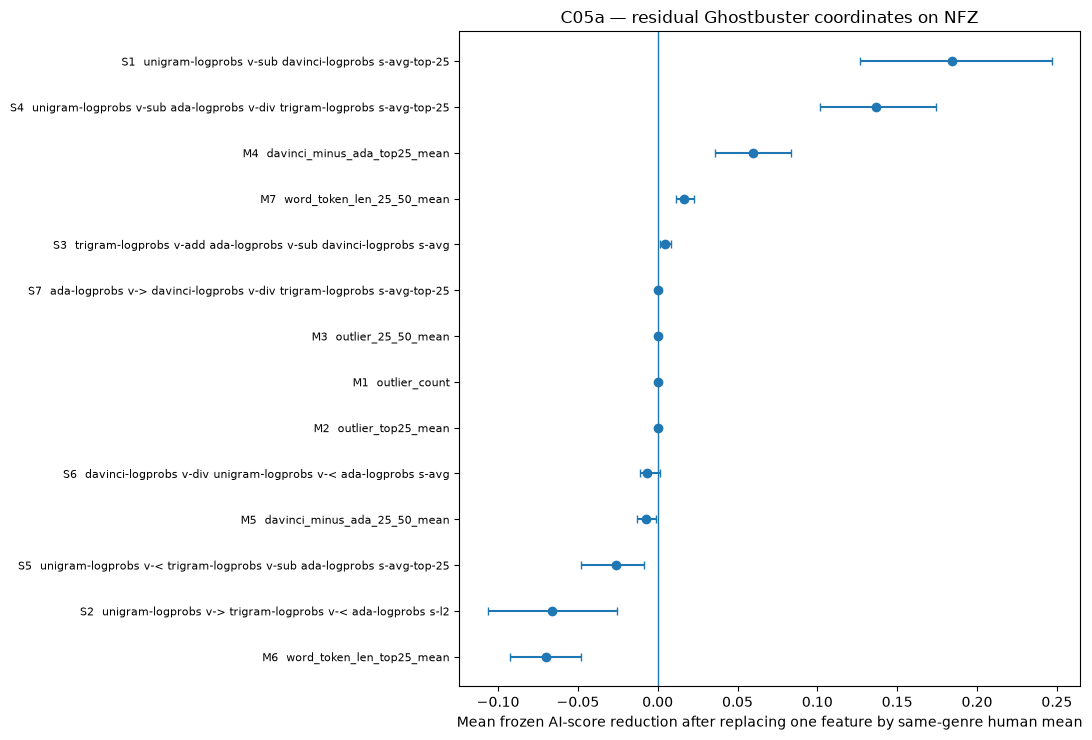

In [9]:
# Figure 1: exact one-coordinate frozen-score reduction.
plot_df = audit.sort_values("mean_score_drop_if_human_mean", ascending=True).copy()
x = plot_df["mean_score_drop_if_human_mean"].to_numpy()
lo = plot_df["score_drop_CI_low"].to_numpy()
hi = plot_df["score_drop_CI_high"].to_numpy()
y = np.arange(len(plot_df))

fig, ax = plt.subplots(figsize=(11, 7.5))
ax.errorbar(
    x, y,
    xerr=np.vstack([x - lo, hi - x]),
    fmt="o", capsize=3
)
ax.axvline(0, linewidth=1)
ax.set_yticks(y)
ax.set_yticklabels([
    f"{fid}  {name}"
    for fid, name in zip(plot_df["feature_id"], plot_df["feature"])
], fontsize=8)
ax.set_xlabel("Mean frozen AI-score reduction after replacing one feature by same-genre human mean")
ax.set_title("C05a — residual Ghostbuster coordinates on NFZ")
fig.tight_layout()

for suffix in ("png", "pdf"):
    fig.savefig(
        FIG / f"C05a_Ghostbuster_NFZ_feature_counterfactual.{suffix}",
        dpi=300, bbox_inches="tight"
    )
    fig.savefig(
        OUT / f"C05a_Ghostbuster_NFZ_feature_counterfactual.{suffix}",
        dpi=300, bbox_inches="tight"
    )
plt.show()


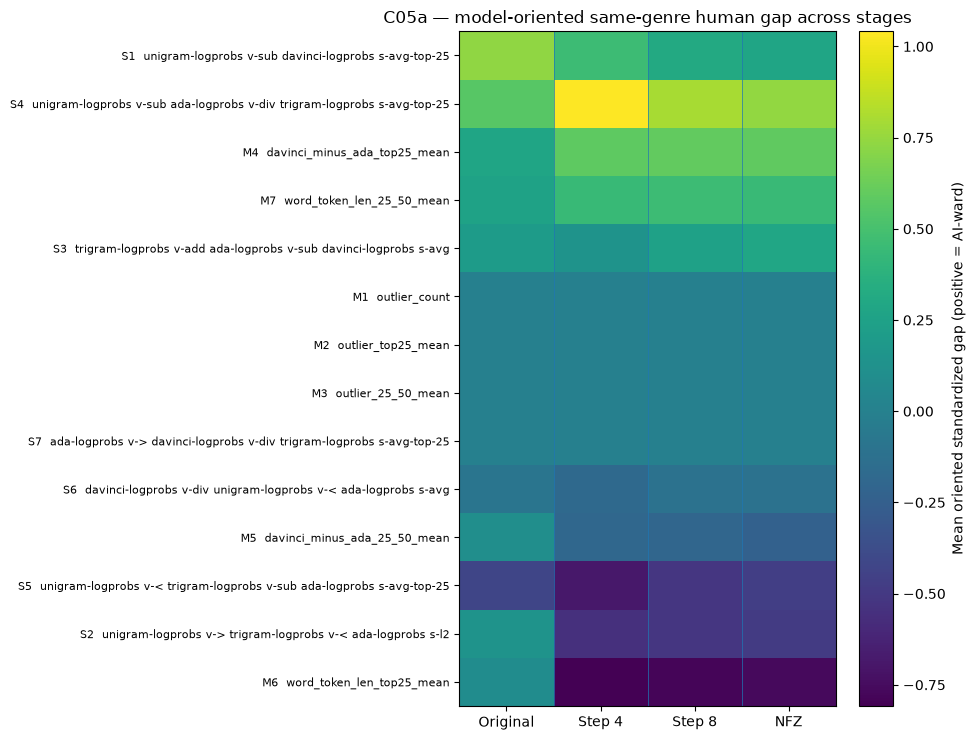

In [10]:
# Figure 2: Original -> Step 4 -> Step 8 -> NFZ trajectory for all 14 coordinates.
mat = traj_pivot.to_numpy(float)

fig, ax = plt.subplots(figsize=(9.5, 7.5))
im = ax.imshow(mat, aspect="auto")
ax.axvline(0.5, linewidth=.5)
ax.axvline(1.5, linewidth=.5)
ax.axvline(2.5, linewidth=.5)

ax.set_xticks(np.arange(len(stage_order)))
ax.set_xticklabels(["Original", "Step 4", "Step 8", "NFZ"])
ax.set_yticks(np.arange(len(rank_order)))
ax.set_yticklabels(
    [f"{FEATURE_ID[f]}  {f}" for f in rank_order],
    fontsize=8
)
ax.set_title("C05a — model-oriented same-genre human gap across stages")
cbar = fig.colorbar(im, ax=ax)
cbar.set_label("Mean oriented standardized gap (positive = AI-ward)")
fig.tight_layout()

for suffix in ("png", "pdf"):
    fig.savefig(
        FIG / f"C05a_Ghostbuster_stage_feature_gap.{suffix}",
        dpi=300, bbox_inches="tight"
    )
    fig.savefig(
        OUT / f"C05a_Ghostbuster_stage_feature_gap.{suffix}",
        dpi=300, bbox_inches="tight"
    )
plt.show()


## 5. Inspect the leading residuals case-by-case

This cell prints the leading features from the exact counterfactual ranking and the NFZ cases furthest onto the AI side. It is intentionally descriptive: **do not choose an edit operator from the detector score alone**. The next intervention should first understand what the underlying stream/expression actually measures and whether a semantically clean manipulation exists.


In [11]:
TOP_K = min(7, len(audit))
top_features = audit.head(TOP_K)["feature"].tolist()

print("Top residual coordinates by exact frozen-score counterfactual:\n")
for r in audit.head(TOP_K).itertuples(index=False):
    print(
        f"{r.rank:>2}. {r.feature_id} {r.feature}\n"
        f"    family={r.family}; AI direction={r.AI_direction}; "
        f"oriented z-gap={r.oriented_z_gap_mean:+.4f}; "
        f"score drop={r.mean_score_drop_if_human_mean:+.5f} "
        f"[{r.score_drop_CI_low:+.5f}, {r.score_drop_CI_high:+.5f}]; "
        f"univariate AUC={r.oriented_univariate_AUROC:.4f}"
    )

case_views = {}
for feature in top_features:
    v = (
        per_case_cf.loc[per_case_cf["feature"].eq(feature)]
        .sort_values("oriented_z_gap", ascending=False)
        .head(12)
        .copy()
    )
    case_views[feature] = v
    print("\n", "=" * 110)
    print(FEATURE_ID[feature], feature)
    display(v[[
        "case_id", "domain", "raw_value", "human_mean", "human_median",
        "oriented_z_gap", "original_AI_score",
        "counterfactual_AI_score", "score_drop"
    ]])

# Compact machine-readable shortlist for the next notebook/turn.
audit.head(TOP_K).to_csv(OUT / "top_residual_features.csv", index=False)
print("\nSaved:", OUT / "top_residual_features.csv")


Top residual coordinates by exact frozen-score counterfactual:

 1. S1 unigram-logprobs v-sub davinci-logprobs s-avg-top-25
    family=symbolic; AI direction=lower; oriented z-gap=+0.2790; score drop=+0.18440 [+0.12643, +0.24682]; univariate AUC=0.7717
 2. S4 unigram-logprobs v-sub ada-logprobs v-div trigram-logprobs s-avg-top-25
    family=symbolic; AI direction=lower; oriented z-gap=+0.7413; score drop=+0.13687 [+0.10158, +0.17400]; univariate AUC=0.7687
 3. M4 davinci_minus_ada_top25_mean
    family=handcrafted; AI direction=lower; oriented z-gap=+0.5903; score drop=+0.05952 [+0.03593, +0.08326]; univariate AUC=0.6609
 4. M7 word_token_len_25_50_mean
    family=handcrafted; AI direction=lower; oriented z-gap=+0.4430; score drop=+0.01660 [+0.01116, +0.02250]; univariate AUC=0.6896
 5. S3 trigram-logprobs v-add ada-logprobs v-sub davinci-logprobs s-avg
    family=symbolic; AI direction=higher; oriented z-gap=+0.2838; score drop=+0.00486 [+0.00158, +0.00817]; univariate AUC=0.5864
 6. 

,case_id,domain,raw_value,human_mean,human_median,oriented_z_gap,original_AI_score,counterfactual_AI_score,score_drop
426,gate_0089,recipes,-0.013776,-0.000381,-0.000225,2.439665,0.999143,0.064173,0.934970
400,gate_0038,reddit,-0.013173,0.000067,0.000310,2.411660,0.999910,0.345508,0.654403
399,gate_0037,recipes,-0.006488,-0.000381,-0.000225,1.112344,0.985806,0.423867,0.561939
397,gate_0030,news,-0.003660,0.000399,0.000303,0.739348,0.875859,0.242334,0.633525
416,gate_0074,abstracts,-0.003728,-0.000080,-0.000070,0.664428,0.735167,0.158916,0.576251
428,gate_0092,abstracts,-0.003497,-0.000080,-0.000070,0.622354,0.892447,0.397903,0.494544
413,gate_0069,abstracts,-0.003217,-0.000080,-0.000070,0.571234,0.310811,0.039876,0.270936
422,gate_0082,wiki,-0.002669,0.000147,0.000283,0.512968,0.813729,0.343643,0.470086
387,gate_0019,reddit,-0.002533,0.000067,0.000310,0.473667,0.768395,0.315950,0.452445
402,gate_0046,abstracts,-0.002610,-0.000080,-0.000070,0.460698,0.648926,0.212849,0.436077



S4 unigram-logprobs v-sub ada-logprobs v-div trigram-logprobs s-avg-top-25


,case_id,domain,raw_value,human_mean,human_median,oriented_z_gap,original_AI_score,counterfactual_AI_score,score_drop
561,gate_0037,recipes,-2.506711,0.515424,0.435411,2.419254,0.985806,0.842036,0.143770
578,gate_0074,abstracts,-2.543915,0.290421,0.164381,2.268919,0.735167,0.205882,0.529285
550,gate_0020,reviews,0.006648,2.162948,2.149384,1.726143,0.458240,0.115454,0.342786
549,gate_0019,reddit,-1.006427,1.113378,0.885364,1.696928,0.768395,0.346849,0.421546
560,gate_0035,books,-0.464974,1.550404,1.215396,1.613333,0.645181,0.239775,0.405405
559,gate_0030,news,-0.595529,1.384714,1.231348,1.585207,0.875859,0.556820,0.319039
562,gate_0038,reddit,-0.843050,1.113378,0.885364,1.566143,0.999910,0.999524,0.000386
543,gate_0005,reddit,-0.803146,1.113378,0.885364,1.534199,0.788493,0.416827,0.371666
579,gate_0075,books,-0.353870,1.550404,1.215396,1.524394,0.738128,0.350485,0.387643
588,gate_0089,recipes,-1.349471,0.515424,0.435411,1.492870,0.999143,0.995965,0.003178



M4 davinci_minus_ada_top25_mean


...


M1 outlier_count


,case_id,domain,raw_value,human_mean,human_median,oriented_z_gap,original_AI_score,counterfactual_AI_score,score_drop
0,gate_0001,abstracts,0.0,0.0,0.0,0.0,0.285047,0.285047,0.000000e+00
1,gate_0003,news,0.0,0.0,0.0,0.0,0.208952,0.208952,-2.775558e-17
2,gate_0004,recipes,0.0,0.0,0.0,0.0,0.065381,0.065381,0.000000e+00
3,gate_0005,reddit,0.0,0.0,0.0,0.0,0.788493,0.788493,0.000000e+00
4,gate_0007,wiki,0.0,0.0,0.0,0.0,0.744739,0.744739,0.000000e+00
5,gate_0015,abstracts,0.0,0.0,0.0,0.0,0.133450,0.133450,-2.775558e-17
6,gate_0016,books,0.0,0.0,0.0,0.0,0.346046,0.346046,-5.551115e-17
7,gate_0017,news,0.0,0.0,0.0,0.0,0.540459,0.540459,0.000000e+00
8,gate_0018,recipes,0.0,0.0,0.0,0.0,0.026326,0.026326,-1.040834e-17
9,gate_0019,reddit,0.0,0.0,0.0,0.0,0.768395,0.768395,0.000000e+00



M2 outlier_top25_mean


,case_id,domain,raw_value,human_mean,human_median,oriented_z_gap,original_AI_score,counterfactual_AI_score,score_drop
54,gate_0001,abstracts,0.0,0.0,0.0,0.0,0.285047,0.285047,0.000000e+00
55,gate_0003,news,0.0,0.0,0.0,0.0,0.208952,0.208952,-2.775558e-17
56,gate_0004,recipes,0.0,0.0,0.0,0.0,0.065381,0.065381,0.000000e+00
57,gate_0005,reddit,0.0,0.0,0.0,0.0,0.788493,0.788493,0.000000e+00
58,gate_0007,wiki,0.0,0.0,0.0,0.0,0.744739,0.744739,0.000000e+00
59,gate_0015,abstracts,0.0,0.0,0.0,0.0,0.133450,0.133450,-2.775558e-17
60,gate_0016,books,0.0,0.0,0.0,0.0,0.346046,0.346046,-5.551115e-17
61,gate_0017,news,0.0,0.0,0.0,0.0,0.540459,0.540459,0.000000e+00
62,gate_0018,recipes,0.0,0.0,0.0,0.0,0.026326,0.026326,-1.040834e-17
63,gate_0019,reddit,0.0,0.0,0.0,0.0,0.768395,0.768395,0.000000e+00



Saved: ../results/causal/C05a_Ghostbuster_feature_audit/top_residual_features.csv


## Interpretation rule for C05b

Use the audit in this order:

1. **Primary:** positive `mean_score_drop_if_human_mean` with a CI mostly above zero.
2. **Support:** positive model-oriented human gap on many of the 54 cases.
3. **Support:** univariate oriented AUROC above 0.5.
4. **Mechanism check:** inspect the feature expression and the cases driving it before designing any intervention.

A feature can rank highly because it is correlated with another coordinate. The one-feature replacement is deliberately a **diagnostic counterfactual**, not a claim that independently editing that scalar in text will reproduce the same score change.

The next step should audit the **highest-ranked interpretable coordinate or coherent feature family**, not blindly optimize all 14 at once.


/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████████████████████████████████████████████████████████████████████████| 310/310 [00:00<00:00, 1128.57it/s]
/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/nltk/downloader.py:1076: UserWarning: NLTK will not authorize the non-private download directory '/home/user/nltk_data': it (or an ancestor) is world- or group-writable, so another local user could plant files there. Choose a private location such as ~/nltk_data.
  for msg in self.incr_download(info_or_id, download_dir, force):
NFZ U/F: 100%|██████████████████████████████████████████████████████████████████████████████████████████| 54/54 [00:03<00:00, 17.04it/s]

Saved: ../results/causal/C05a_Ghostbuster_feature_audit/NFZ_UF_measurements.parquet


,feature_id,feature,metric,n,pearson_r,pearson_p,spearman_rho,spearman_p
0,S1,unigram-logprobs v-sub davinci-logprobs s-avg-top-25,U32,8,-0.552231,0.155817,-0.619048,0.101733
1,S1,unigram-logprobs v-sub davinci-logprobs s-avg-top-25,U128,8,-0.583077,0.129250,-0.666667,0.070988
2,S1,unigram-logprobs v-sub davinci-logprobs s-avg-top-25,U256,8,-0.744479,0.034124,-0.761905,0.028005
3,S1,unigram-logprobs v-sub davinci-logprobs s-avg-top-25,F,8,-0.240616,0.565956,-0.142857,0.735765
4,S4,unigram-logprobs v-sub ada-logprobs v-div trigram-logprobs s-avg-top-25,U32,8,-0.474519,0.234813,-0.738095,0.036553
5,S4,unigram-logprobs v-sub ada-logprobs v-div trigram-logprobs s-avg-top-25,U128,8,-0.431899,0.285260,-0.690476,0.057990
6,S4,unigram-logprobs v-sub ada-logprobs v-div trigram-logprobs s-avg-top-25,U256,8,-0.470515,0.239342,-0.595238,0.119530
7,S4,unigram-logprobs v-sub ada-logprobs v-div trigram-logprobs s-avg-top-25,F,8,0.219788,0.600977,0.261905,0.530923
8,M4,davinci_minus_ada_top25_mean,U32,8,0.142726,0.736001,0.261905,0.530923
9,M4,davinci_minus_ada_top25_mean,U128,8,0.485802,0.222288,0.619048,0.101733


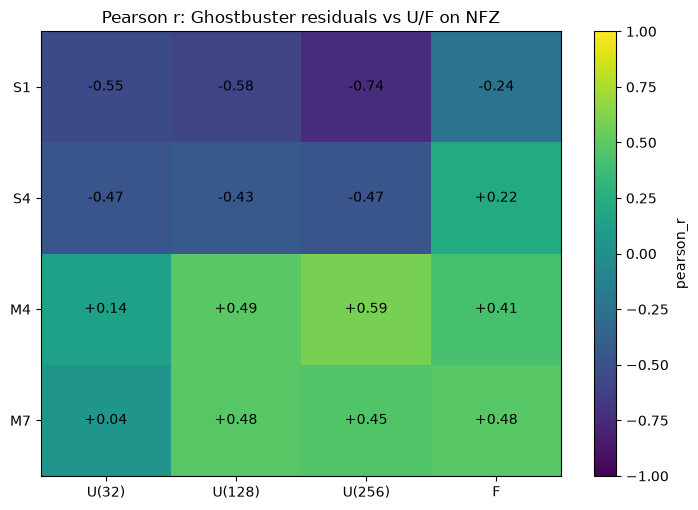

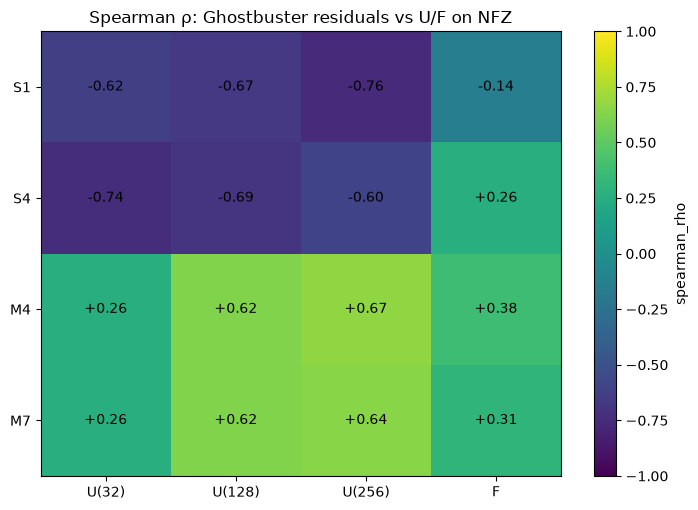

Common eligible n by pair:


metric,U32,U128,U256,F
feature_id,,,,
S1,8,8,8,8
S4,8,8,8,8
M4,8,8,8,8
M7,8,8,8,8


In [12]:
# U/F ↔ top Ghostbuster residuals on NFZ.
# Reuses the paper's frozen U/F definitions: Qwen3-0.6B-Base, 384-token prefix,
# U(k)=L8-Lk at 8 evenly spaced targets, and 200-shuffle recurrence frontloading.
import re,nltk,torch
import torch.nn.functional as F
from tqdm.auto import tqdm
from scipy.stats import pearsonr,spearmanr
from transformers import AutoTokenizer,AutoModelForCausalLM
from nltk.tokenize import sent_tokenize
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

UF_CACHE=OUT/"NFZ_UF_measurements.parquet"
STEP10_TEXT=ROOT/"results/causal/C04c_CARDINAL_controlled_insertion/16d25f12a76b/texts_after_CARDINAL_step10.csv"
assert STEP10_TEXT.exists(),STEP10_TEXT

top_ids=["S1","S4","M4","M7"]
id_to_feature={v:k for k,v in FEATURE_ID.items()}
top_features=[id_to_feature[x] for x in top_ids]

texts=pd.read_csv(STEP10_TEXT,keep_default_na=False)[["case_id","text"]]
work=nfz.merge(texts,on="case_id",how="left",validate="one_to_one")
assert work.text.notna().all()

if UF_CACHE.exists():
    uf=pd.read_parquet(UF_CACHE)
    print("Loaded cached U/F:",UF_CACHE)
else:
    SCORER="Qwen/Qwen3-0.6B-Base"; PREFIX=384; KS=[8,32,128,256]
    device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
    tok=AutoTokenizer.from_pretrained(SCORER)
    model=AutoModelForCausalLM.from_pretrained(
        SCORER,dtype=torch.float16 if device.type=="cuda" else torch.float32
    ).to(device).eval()

    @torch.inference_mode()
    def context_utility(text):
        ids=tok(str(text),add_special_tokens=False)["input_ids"]
        if len(ids)<PREFIX:return None
        ids=ids[:PREFIX]
        pos=np.unique(np.linspace(256,len(ids)-1,8,dtype=int))
        losses={}
        for k in KS:
            x=torch.tensor([ids[p-k:p] for p in pos],device=device)
            y=torch.tensor([ids[p] for p in pos],device=device)
            logits=model(input_ids=x,logits_to_keep=1).logits[:,-1,:].float()
            losses[k]=float((-F.log_softmax(logits,dim=-1)[torch.arange(len(y),device=device),y]).mean().cpu())
        return {"U32":losses[8]-losses[32],"U128":losses[8]-losses[128],"U256":losses[8]-losses[256]}

    nltk.download("punkt",quiet=True)
    try:nltk.download("punkt_tab",quiet=True)
    except Exception:pass
    WORD_RE=re.compile(r"[a-zA-Z][a-zA-Z'-]*")
    STOP=set(ENGLISH_STOP_WORDS)
    BINS=[(0,32),(33,64),(65,96),(97,128),(129,160),(161,192),(193,224),(225,256),(257,320)]

    def frontloading(text):
        ids=tok(str(text),add_special_tokens=False)["input_ids"]
        if len(ids)<PREFIX:return np.nan
        prefix=tok.decode(ids[:PREFIX],skip_special_tokens=True)
        sents=[s.strip() for s in sent_tokenize(prefix) if s.strip()]
        if len(sents)<2:return np.nan
        sets=[];centers=[];cursor=0
        for s in sents:
            sid=tok(s,add_special_tokens=False)["input_ids"]
            centers.append((cursor+cursor+len(sid))/2);cursor+=len(sid)
            sets.append({w for w in WORD_RE.findall(s.lower()) if w not in STOP and len(w)>=3})
        centers=np.asarray(centers,float);n=len(sets)
        J=np.full((n,n),np.nan,float);np.fill_diagonal(J,1.)
        for i in range(n):
            for j in range(i+1,n):
                union=sets[i]|sets[j]
                v=np.nan if not union else len(sets[i]&sets[j])/len(union)
                J[i,j]=J[j,i]=v
        pair={}
        for b in BINS:
            lo,hi=b;ii=[];jj=[]
            for i in range(n):
                for j in range(i+1,n):
                    d=centers[j]-centers[i]
                    if lo<=d<=hi:ii.append(i);jj.append(j)
            pair[b]=(np.asarray(ii,int),np.asarray(jj,int))
        def mean_pairs(mat,ii,jj):
            if len(ii)==0:return np.nan
            v=mat[ii,jj];v=v[np.isfinite(v)]
            return float(v.mean()) if len(v) else np.nan
        observed={b:mean_pairs(J,*pair[b]) for b in BINS}
        rng=np.random.default_rng(42);acc={b:[] for b in BINS}
        for _ in range(200):
            order=rng.permutation(n)
            for b in BINS:
                ii,jj=pair[b]
                if len(ii)==0:continue
                v=J[order[ii],order[jj]];v=v[np.isfinite(v)]
                if len(v):acc[b].append(float(v.mean()))
        excess=[]
        for b in BINS:
            sh=float(np.mean(acc[b])) if acc[b] else np.nan
            excess.append(observed[b]-sh if np.isfinite(observed[b]) and np.isfinite(sh) else np.nan)
        near=np.nanmean(excess[:3]) if np.isfinite(excess[:3]).any() else np.nan
        far=np.nanmean(excess[-3:]) if np.isfinite(excess[-3:]).any() else np.nan
        return near-far if np.isfinite(near) and np.isfinite(far) else np.nan

    rows=[]
    for r in tqdm(work[["case_id","text"]].itertuples(index=False),total=len(work),desc="NFZ U/F"):
        u=context_utility(r.text)
        rows.append({"case_id":r.case_id,
                     "U32":np.nan if u is None else u["U32"],
                     "U128":np.nan if u is None else u["U128"],
                     "U256":np.nan if u is None else u["U256"],
                     "F":frontloading(r.text)})
    uf=pd.DataFrame(rows);uf.to_parquet(UF_CACHE,index=False)
    del model
    if torch.cuda.is_available():torch.cuda.empty_cache()
    print("Saved:",UF_CACHE)

corr=work[["case_id","domain"]+top_features].merge(uf,on="case_id",validate="one_to_one")
metrics=["U32","U128","U256","F"]
rows=[]
for fid,feat in zip(top_ids,top_features):
    for m in metrics:
        z=corr[[feat,m]].dropna()
        pr,pp=pearsonr(z[feat],z[m]);sr,sp=spearmanr(z[feat],z[m])
        rows.append({"feature_id":fid,"feature":feat,"metric":m,"n":len(z),
                     "pearson_r":pr,"pearson_p":pp,"spearman_rho":sr,"spearman_p":sp})
corr_table=pd.DataFrame(rows)
display(corr_table)
corr_table.to_csv(OUT/"NFZ_UF_Ghostbuster_correlations.csv",index=False)

for stat,title,stem in [
    ("pearson_r","Pearson r: Ghostbuster residuals vs U/F on NFZ","C05a_Ghostbuster_UF_Pearson"),
    ("spearman_rho","Spearman ρ: Ghostbuster residuals vs U/F on NFZ","C05a_Ghostbuster_UF_Spearman")
]:
    mat=corr_table.pivot(index="feature_id",columns="metric",values=stat).loc[top_ids,metrics]
    fig,ax=plt.subplots(figsize=(7.2,5.2))
    im=ax.imshow(mat.to_numpy(float),vmin=-1,vmax=1,aspect="auto")
    ax.set_xticks(range(len(metrics)));ax.set_xticklabels(["U(32)","U(128)","U(256)","F"])
    ax.set_yticks(range(len(top_ids)));ax.set_yticklabels(top_ids)
    for i in range(len(top_ids)):
        for j in range(len(metrics)):ax.text(j,i,f"{mat.iloc[i,j]:+.2f}",ha="center",va="center")
    ax.set_title(title)
    fig.colorbar(im,ax=ax,label=stat)
    fig.tight_layout()
    for folder in [OUT,FIG]:
        fig.savefig(folder/f"{stem}.png",dpi=300,bbox_inches="tight")
        fig.savefig(folder/f"{stem}.pdf",bbox_inches="tight")
    plt.show()

print("Common eligible n by pair:")
display(corr_table.pivot(index="feature_id",columns="metric",values="n").loc[top_ids,metrics])


,feature_id,feature,metric,n,pearson_r,pearson_p,spearman_rho,spearman_p
0,S1,unigram-logprobs v-sub davinci-logprobs s-avg-top-25,G8_32,8,-0.552231,0.155817,-0.619048,0.101733
1,S1,unigram-logprobs v-sub davinci-logprobs s-avg-top-25,G32_128,8,-0.329475,0.425486,-0.404762,0.319889
2,S1,unigram-logprobs v-sub davinci-logprobs s-avg-top-25,G128_256,8,-0.347478,0.399023,-0.142857,0.735765
3,S4,unigram-logprobs v-sub ada-logprobs v-div trigram-logprobs s-avg-top-25,G8_32,8,-0.474519,0.234813,-0.738095,0.036553
4,S4,unigram-logprobs v-sub ada-logprobs v-div trigram-logprobs s-avg-top-25,G32_128,8,-0.199343,0.636016,-0.095238,0.822505
5,S4,unigram-logprobs v-sub ada-logprobs v-div trigram-logprobs s-avg-top-25,G128_256,8,-0.070787,0.867717,0.190476,0.651401
6,M4,davinci_minus_ada_top25_mean,G8_32,8,0.142726,0.736001,0.261905,0.530923
7,M4,davinci_minus_ada_top25_mean,G32_128,8,0.491239,0.216379,0.547619,0.160026
8,M4,davinci_minus_ada_top25_mean,G128_256,8,0.227962,0.587148,0.023810,0.955374
9,M7,word_token_len_25_50_mean,G8_32,8,0.044414,0.916832,0.261905,0.530923


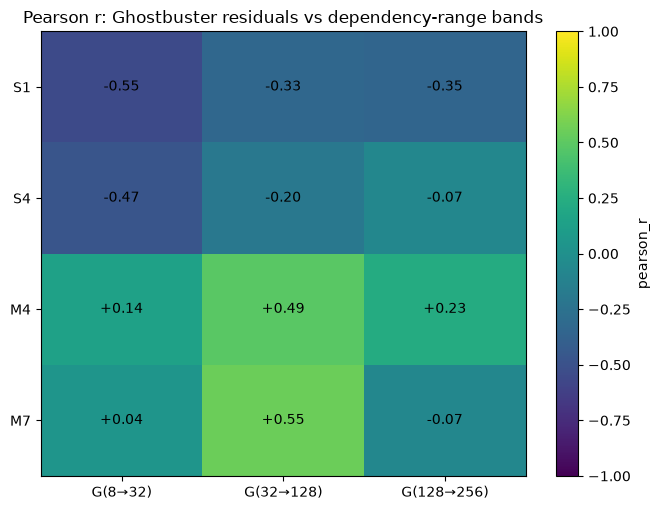

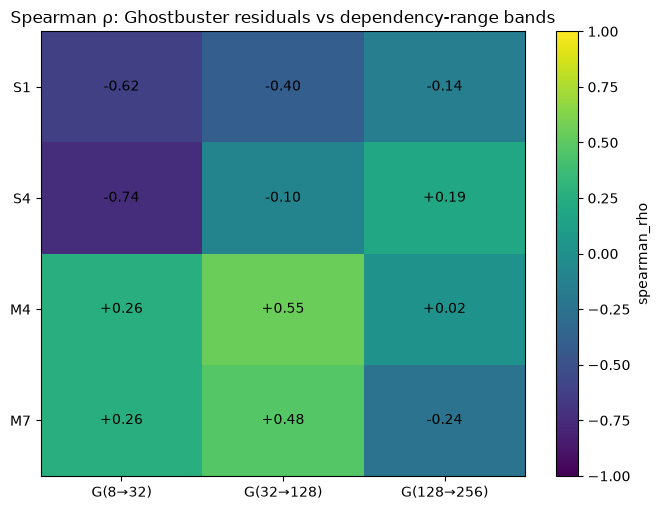

In [13]:
# Dependency-band audit: does Ghostbuster correlate with specifically longer-range utility?
band = corr.copy()
band["G8_32"] = band["U32"]
band["G32_128"] = band["U128"] - band["U32"]
band["G128_256"] = band["U256"] - band["U128"]

band_metrics=["G8_32","G32_128","G128_256"]
rows=[]
for fid,feat in zip(top_ids,top_features):
    for m in band_metrics:
        z=band[[feat,m]].dropna()
        pr,pp=pearsonr(z[feat],z[m])
        sr,sp=spearmanr(z[feat],z[m])
        rows.append({
            "feature_id":fid,"feature":feat,"metric":m,"n":len(z),
            "pearson_r":pr,"pearson_p":pp,
            "spearman_rho":sr,"spearman_p":sp
        })

band_corr=pd.DataFrame(rows)
display(band_corr)
band_corr.to_csv(OUT/"NFZ_dependency_band_Ghostbuster_correlations.csv",index=False)

for stat,title,stem in [
    ("pearson_r","Pearson r: Ghostbuster residuals vs dependency-range bands",
     "C05a_Ghostbuster_dependency_bands_Pearson"),
    ("spearman_rho","Spearman ρ: Ghostbuster residuals vs dependency-range bands",
     "C05a_Ghostbuster_dependency_bands_Spearman")
]:
    mat=band_corr.pivot(index="feature_id",columns="metric",values=stat).loc[top_ids,band_metrics]
    fig,ax=plt.subplots(figsize=(6.8,5.2))
    im=ax.imshow(mat.to_numpy(float),vmin=-1,vmax=1,aspect="auto")
    ax.set_xticks(range(3))
    ax.set_xticklabels(["G(8→32)","G(32→128)","G(128→256)"])
    ax.set_yticks(range(len(top_ids)))
    ax.set_yticklabels(top_ids)

    for i in range(len(top_ids)):
        for j in range(3):
            ax.text(j,i,f"{mat.iloc[i,j]:+.2f}",ha="center",va="center")

    ax.set_title(title)
    fig.colorbar(im,ax=ax,label=stat)
    fig.tight_layout()

    for folder in [OUT,FIG]:
        fig.savefig(folder/f"{stem}.png",dpi=300,bbox_inches="tight")
        fig.savefig(folder/f"{stem}.pdf",bbox_inches="tight")
    plt.show()